<a href="https://colab.research.google.com/github/anayamgreen/A05-pca/blob/main/A5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [7]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
#Counter(token_freq).most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

One thing I noticed about this histogram is that there is a big right skew, therefore there are more frequency of words

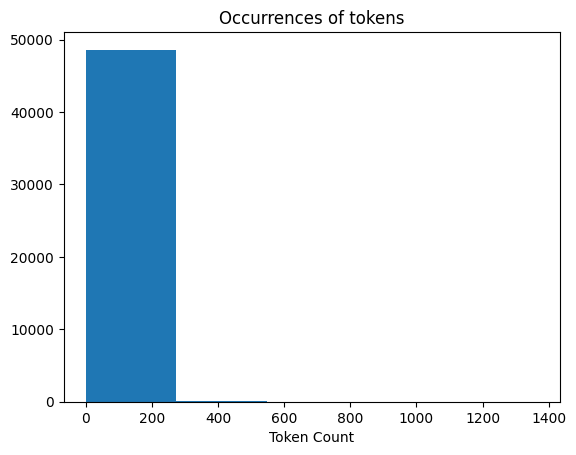

In [12]:
# Load in data
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.hist(token_count.values(), bins=5)
plt.title("Occurrences of tokens")
plt.xlabel("Token Count")
plt.ylabel("Frequency")
plt.show()

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

In [33]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression

df = pd.read_parquet("Phishing_clean.parquet")

print(df.head())
print(df.columns.to_numpy())

eval_X_raw = df.drop(columns=["Email Type"])
eval_y = df["Email Type"]
(
    eval_X_train_raw,
    eval_X_valid_raw,
    eval_y_train,
    eval_y_valid,
) = train_test_split(
    eval_X_raw, eval_y, test_size=0.20, random_state=65
)

eval_scaler = MinMaxScaler()
eval_X_train_scaled = eval_scaler.fit_transform(eval_X_train_raw)
eval_X_valid_scaled = eval_scaler.transform(eval_X_valid_raw)



# Multiple linear regression
def mlr(X, y):
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    y_hat = X @ b
    residuals = y - y_hat
    sse = np.inner(residuals, residuals)
    rsq = 1 - sse / np.inner(y - np.mean(y), y - np.mean(y))
    return {"b": b, "y_hat": y_hat, "residuals": residuals,
            "rsq": rsq, "SSE": sse}

# Add intercept
eval_X_train_raw = eval_X_train_raw.copy()
eval_X_valid_raw = eval_X_valid_raw.copy()

eval_X_train_raw["(Intercept)"] = 1
eval_X_valid_raw["(Intercept)"] = 1


#intercept
cols = ["(Intercept)"] + [
    col for col in eval_X_train_raw.columns
    if col != "(Intercept)"
]
eval_X_train_raw = eval_X_train_raw[cols]
eval_X_valid_raw = eval_X_valid_raw[cols]


#fir regression for training data
fit = mlr(eval_X_train_raw, eval_y_train)

print("Training R-squared:", round(fit["rsq"], 4))


#use the training coefficients to predict the test data
eval_y_hat_valid = eval_X_valid_raw @ fit["b"]

eval_valid_residuals = eval_y_valid - eval_y_hat_valid
eval_valid_sse = np.inner(
    eval_valid_residuals,
    eval_valid_residuals
)

eval_valid_rsq = 1 - eval_valid_sse / np.inner(
    eval_y_valid - np.mean(eval_y_valid),
    eval_y_valid - np.mean(eval_y_valid)
)

print("Test R-squared:", round(eval_valid_rsq, 4))


   Email Type  new  date  get  please  enron  like  2002  would  one  ...  \
0           0    0     0    0       0      0     0     0      0    0  ...   
1           0    0     0    0       0      0     0     0      0    0  ...   
2           0    1     0    0       0      0     0     0      0    0  ...   
3           1    0     0    0       0      0     0     0      0    1  ...   
4           1    0     0    0       0      0     0     0      0    0  ...   

   ï¿½ï¿½  safety  yap  ypil  maintain  procedures  tip  elizabeth  \
0       0       0    0     0         0           0    0          0   
1       0       0    0     0         0           0    0          0   
2       0       0    0     0         0           0    0          0   
3       0       0    0     0         0           0    0          0   
4       0       0    0     0         0           0    0          0   

   leadership  italian  
0           0        0  
1           0        0  
2           0        0  
3           0   

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

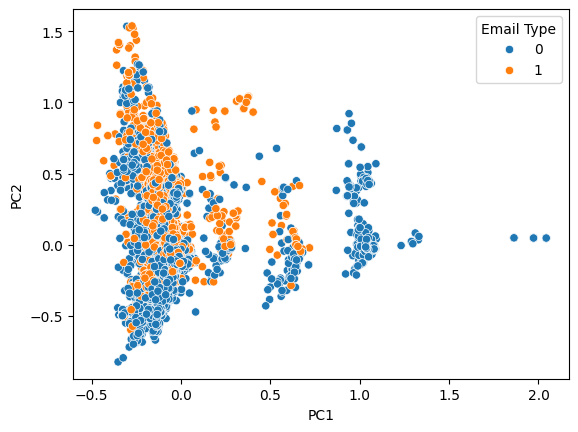

In [34]:

# Data less the outcome variable
X_pca = df.drop(columns=["Email Type", "(Intercept)"], errors="ignore")

# Center the data
Z = X_pca - X_pca.mean()

# Calculate covariance matrix
C = Z.T @ Z / (len(Z) - 1)

# Find eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(C)

# Sort from largest eigenvalue to smallest
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Keep the first two principal components
P = eigenvectors[:, :2]

# Transform the data
X_pca_2 = Z @ P

# Put the two components into a DataFrame for plotting
pca_df = pd.DataFrame({
    "PC1": X_pca_2.iloc[:, 0],
    "PC2": X_pca_2.iloc[:, 1],
    "Email Type": df["Email Type"]
})

# Plot
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Email Type"
)

plt.show()

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [38]:
# Keep the first 2,610 principal components
P_2610 = eigenvectors[:, :2610]

# Transform X into principal components
X_pca_2610 = Z @ P_2610

# Add intercept like in the regression lecture
X_pca_2610["(Intercept)"] = 1

# Put intercept first
cols = ["(Intercept)"] + [
    col for col in X_pca_2610.columns
    if col != "(Intercept)"
]

X_pca_2610 = X_pca_2610[cols]

y = df["Email Type"]
(
    X_pca_train,
    X_pca_test,
    y_pca_train,
    y_pca_test,
) = train_test_split(
    X_pca_2610, y, test_size=0.20, random_state=65
)

fit_pca = mlr(X_pca_train, y_pca_train)
print("Training R-squared:", round(fit_pca["rsq"], 4))


y_hat_pca_test = X_pca_test @ fit_pca["b"]

residuals_pca_test = y_pca_test - y_hat_pca_test
sse_pca_test = np.inner(
    residuals_pca_test,
    residuals_pca_test
)

rsq_pca_test = 1 - sse_pca_test / np.inner(
    y_pca_test - np.mean(y_pca_test),
    y_pca_test - np.mean(y_pca_test)
)

print("Test R-squared:", round(rsq_pca_test, 4))

Training R-squared: 0.767
Test R-squared: 0.6594


**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [ ]:
# Your Phase 1 solution to the problem goes here.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]